# Módulo 01: Hidrodinámica de Ondas y Oleaje Costero (`sedmor.waves`)

En este cuaderno se aplican las herramientas de hidrodinámica de oleaje implementadas a partir de las planillas de cálculo del paquete de modelación de Leo C. van Rijn (2013).

### Objetivos de aprendizaje
1. Evaluar la **relación de dispersión lineal** comparando la solución iterativa exacta con las aproximaciones explícitas de Hunt (1979) y Nielsen (2006), además del **espectro JONSWAP**.
2. Analizar la estructura vertical de la **capa límite oscilatoria de oleaje** y el **decaimiento de altura de ola por fricción** en fondo somero.
3. Simular la **propagación, asomeramiento y rotura** sobre un perfil costero con el modelo espectral de **Battjes y Janssen (1978)** (altura $H_{\text{rms}}$, sobreelevación *wave setup* y corriente longitudinal).
4. Cuantificar la **asimetría y oblicuidad de la velocidad orbital** (Abreu et al.) y el **transporte de fondo inducido por aceleración** (Nielsen).


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sedmor as sm

plt.rcParams["figure.dpi"] = 110
print(f"Librería sedmor v{sm.__version__} cargada correctamente.")


Librería sedmor v0.1.0 cargada correctamente.


## 1. Relación de Dispersión Lineal y Espectro JONSWAP

La relación de dispersión conecta la frecuencia angular $\omega = 2\pi / T$ con el número de onda $k = 2\pi / L$ y la profundidad $h$:
$$\omega^2 = g k \tanh(k h)$$
Compararemos las soluciones para un período $T = 8\,\text{s}$ en un rango de profundidades desde aguas someras ($h = 1\,\text{m}$) hasta aguas profundas ($h = 60\,\text{m}$), y graficaremos el espectro de energía **JONSWAP** para un estado de mar típico de tormenta ($H_s = 3.5\,\text{m}$, $T_p = 9.0\,\text{s}$).


Error máximo de L frente a solución exacta -> Hunt: 0.185% | Nielsen: 5.955%


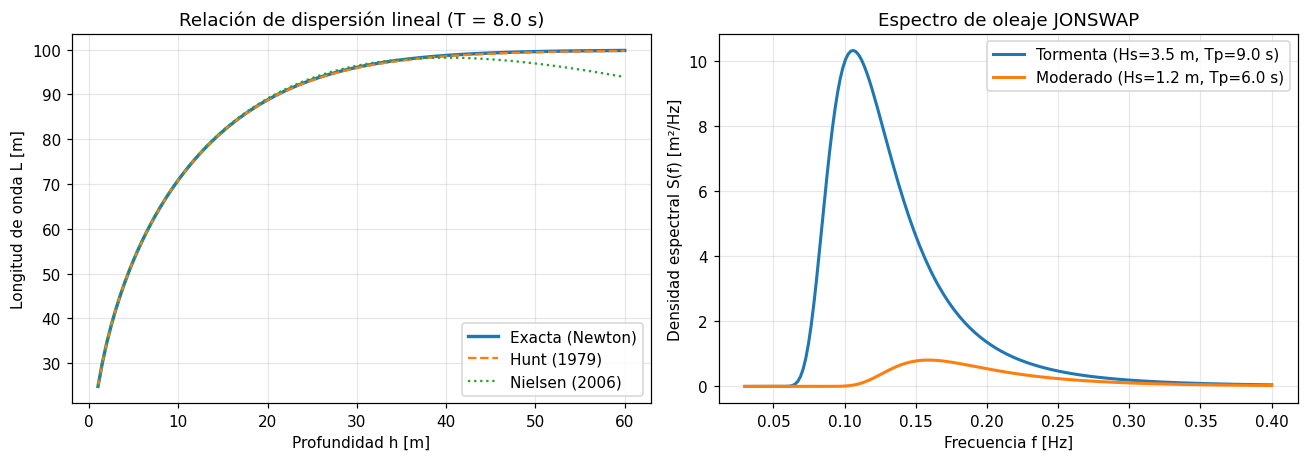

In [2]:
h_vals = np.linspace(1.0, 60.0, 120)
T_wave = 8.0

disp_ex = sm.waves.dispersion_relation(h_vals, T_wave, method="exact")
disp_hu = sm.waves.dispersion_relation(h_vals, T_wave, method="hunt")
disp_ni = sm.waves.dispersion_relation(h_vals, T_wave, method="nielsen")

freqs = np.linspace(0.03, 0.40, 200)
S_calm = sm.waves.jonswap_spectrum(freqs, H_s=1.2, T_p=6.0)
S_storm = sm.waves.jonswap_spectrum(freqs, H_s=3.5, T_p=9.0)

err_hunt = np.max(np.abs(disp_hu["L"] - disp_ex["L"]) / disp_ex["L"]) * 100
err_niel = np.max(np.abs(disp_ni["L"] - disp_ex["L"]) / disp_ex["L"]) * 100
print(f"Error máximo de L frente a solución exacta -> Hunt: {err_hunt:.3f}% | Nielsen: {err_niel:.3f}%")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

ax1.plot(h_vals, disp_ex["L"], label="Exacta (Newton)", lw=2.2)
ax1.plot(h_vals, disp_hu["L"], "--", label="Hunt (1979)")
ax1.plot(h_vals, disp_ni["L"], ":", label="Nielsen (2006)")
ax1.set_xlabel("Profundidad h [m]")
ax1.set_ylabel("Longitud de onda L [m]")
ax1.set_title(f"Relación de dispersión lineal (T = {T_wave:.1f} s)")
ax1.grid(alpha=0.3)
ax1.legend()

ax2.plot(freqs, S_storm, label="Tormenta (Hs=3.5 m, Tp=9.0 s)", lw=2)
ax2.plot(freqs, S_calm, label="Moderado (Hs=1.2 m, Tp=6.0 s)", lw=2)
ax2.set_xlabel("Frecuencia f [Hz]")
ax2.set_ylabel("Densidad espectral S(f) [m²/Hz]")
ax2.set_title("Espectro de oleaje JONSWAP")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


## 2. Capa Límite Oscilatoria y Decaimiento por Fricción

La función `sm.waves.wave_boundary_layer` calcula los perfiles verticales de velocidad $u(z/\delta, t)$ y las tensiones tangenciales de fondo $\tau(t)$ dentro de la capa límite del oleaje. Asimismo, `sm.waves.wave_decay_friction` evalúa la atenuación de la altura de ola sobre una plataforma somera horizontal por disipación por fricción de fondo.


Espesor capa límite delta: 0.0357 m | tau_max: 23.78 N/m²
Decaimiento en 10.0 km: H0=4.00 m -> H_final=2.12 m


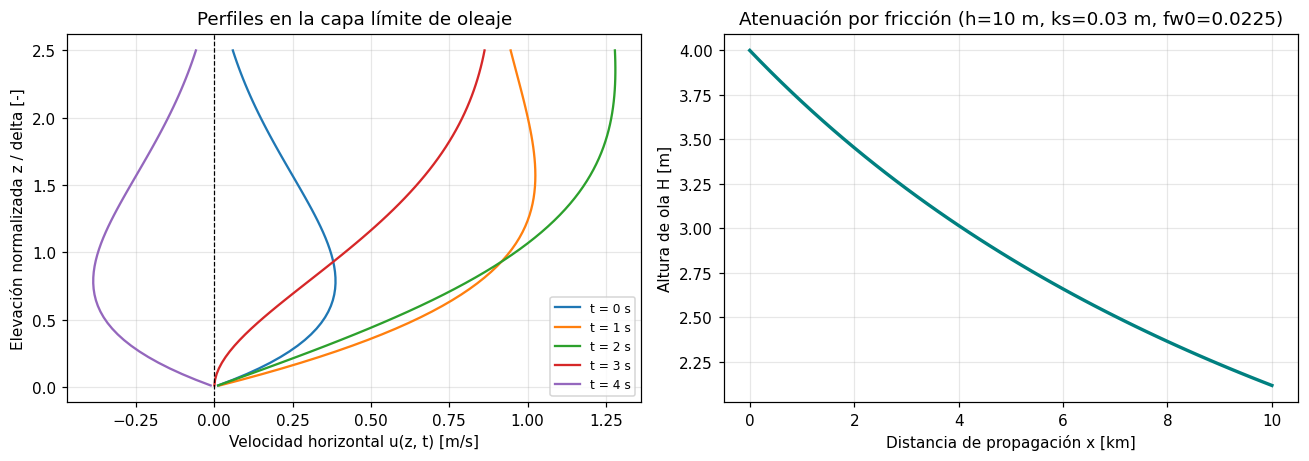

In [3]:
zeta = np.linspace(0.01, 2.5, 60)[:, None]
t_phases = np.array([0.0, 1.0, 2.0, 3.0, 4.0])[None, :]  # s para T=8 s

wbl = sm.waves.wave_boundary_layer(zeta, t_phases, U_max=1.2, T=8.0, eps=0.0005, k=0.25)
decay = sm.waves.wave_decay_friction(h=10.0, H0=4.0, T=10.0, L=None, k_s=0.03, dx=200.0, n_steps=51)

print(f"Espesor capa límite delta: {wbl['delta']:.4f} m | tau_max: {wbl['tau_max']:.2f} N/m²")
print(f"Decaimiento en {decay['x'][-1]/1000:.1f} km: H0={decay['H'][0]:.2f} m -> H_final={decay['H'][-1]:.2f} m")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3))

for j in range(t_phases.shape[1]):
    ax1.plot(wbl["u_t"][:, j], zeta[:, 0], label=f"t = {t_phases[0, j]:.0f} s")
ax1.axvline(0.0, color="k", lw=0.8, ls="--")
ax1.set_xlabel("Velocidad horizontal u(z, t) [m/s]")
ax1.set_ylabel("Elevación normalizada z / delta [-]")
ax1.set_title("Perfiles en la capa límite de oleaje")
ax1.grid(alpha=0.3)
ax1.legend(fontsize=8)

ax2.plot(decay["x"] / 1000.0, decay["H"], color="teal", lw=2.2)
ax2.set_xlabel("Distancia de propagación x [km]")
ax2.set_ylabel("Altura de ola H [m]")
ax2.set_title(f"Atenuación por fricción (h=10 m, ks=0.03 m, fw0={float(np.asarray(decay['f_w']).flat[0]):.4f})")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Propagación y Rotura Costera (Battjes & Janssen, 1978)

Aplicamos `sm.waves.battjes_janssen_profile` sobre una playa con pendiente suave y una barra sumergida para observar cómo evoluciona la altura cuadrática media $H_{\text{rms}}$, la sobreelevación por rotura (*wave setup* $\bar{\eta}$) y la corriente longitudinal $v_{\text{longshore}}$ ante incidencia oblicua ($\theta_0 = 25^\circ$).


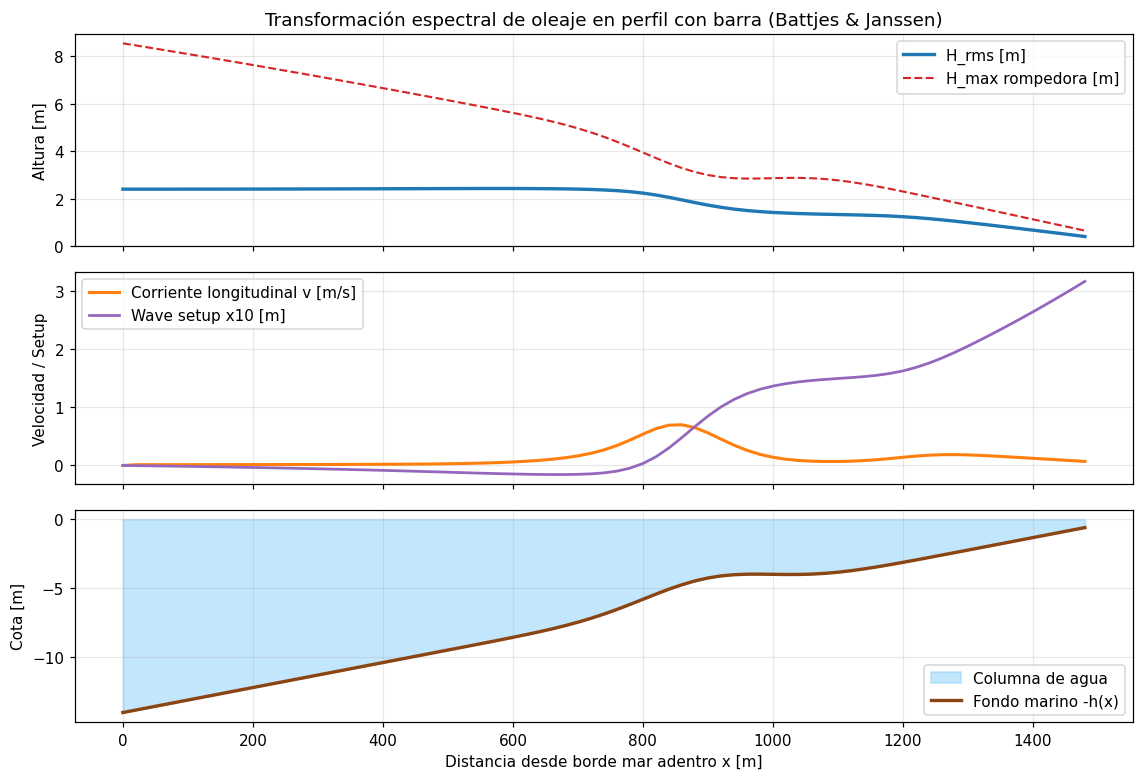

In [4]:
dx = 20.0
nx = 75
x_prof = np.arange(nx) * dx
# Perfil desde h=14 m hasta 0.6 m con una barra sumergida centrada en x=900 m
h_base = np.linspace(14.0, 0.6, nx)
bar = 1.6 * np.exp(-((x_prof - 900.0) / 140.0) ** 2)
h_profile = np.maximum(h_base - bar, 0.5)

bj = sm.waves.battjes_janssen_profile(
    h_profile=h_profile,
    H_rms0=2.4,
    theta0_deg=25.0,
    T=9.0,
    gamma=0.73,
    k_s=0.01,
    dx=dx,
)

fig, axes = plt.subplots(3, 1, figsize=(10.5, 7.2), sharex=True)

axes[0].plot(bj["x"], bj["H_rms"], color="tab:blue", lw=2.2, label="H_rms [m]")
axes[0].plot(bj["x"], bj["H_max"], color="tab:red", ls="--", lw=1.4, label="H_max rompedora [m]")
axes[0].set_ylabel("Altura [m]")
axes[0].set_title("Transformación espectral de oleaje en perfil con barra (Battjes & Janssen)")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(bj["x"], bj["v_longshore"], color="tab:orange", lw=2.0, label="Corriente longitudinal v [m/s]")
axes[1].plot(bj["x"], bj["setup"] * 10.0, color="tab:purple", lw=1.8, label="Wave setup x10 [m]")
axes[1].set_ylabel("Velocidad / Setup")
axes[1].grid(alpha=0.3)
axes[1].legend()

axes[2].fill_between(bj["x"], -bj["h"], 0.0, color="lightskyblue", alpha=0.5, label="Columna de agua")
axes[2].plot(bj["x"], -bj["h"], color="saddlebrown", lw=2.2, label="Fondo marino -h(x)")
axes[2].set_xlabel("Distancia desde borde mar adentro x [m]")
axes[2].set_ylabel("Cota [m]")
axes[2].grid(alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()


## 4. Asimetría de Onda y Transporte por Aceleración

En aguas someras la onda se distorsiona volviéndose asimétrica (crestas agudas, frentes inclinados). Evaluamos la forma temporal de la velocidad orbital cercana al fondo mediante **Abreu et al.** (`abreu_skewness_asymmetry`) y su impacto neto en el transporte de fondo mediante la parametrización de **Nielsen** (`nielsen_acceleration_transport`).


Abreu -> Ur = 1.222 | r = 0.596 | fase phi = -55.1°
Transporte neto por ciclo -> Nielsen: 0.313 kg/(m·s) | van Rijn Stokes: 0.160 kg/(m·s)


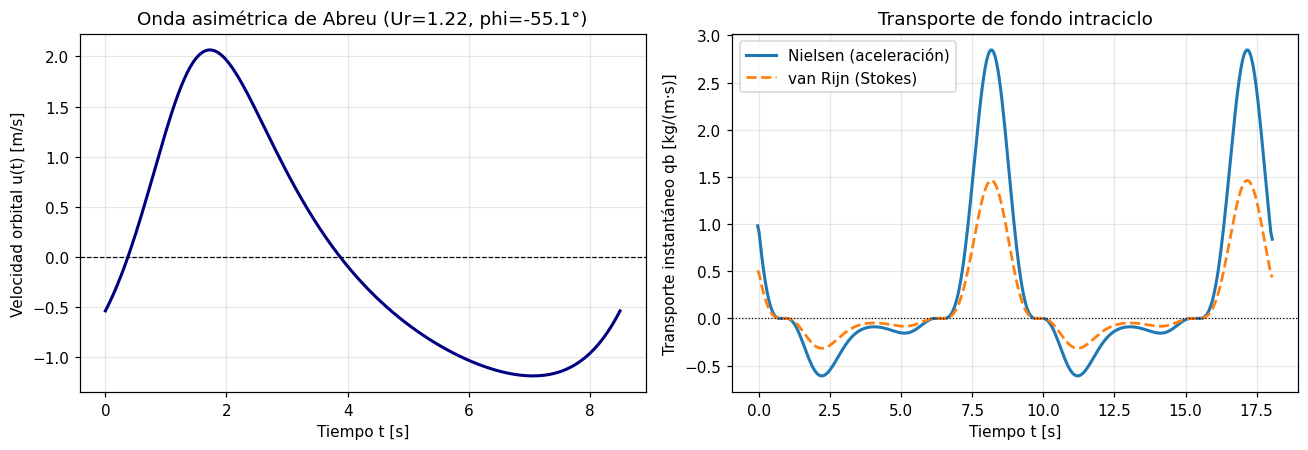

In [5]:
abr = sm.waves.abreu_skewness_asymmetry(H_rms=1.4, h=3.2, T=8.5, dt=0.05)
nie = sm.waves.nielsen_acceleration_transport(
    U1=1.1, U2=0.35, U_for=1.45, U_back=0.70, T=9.0, phase_deg=40.0, d50=0.00021
)

print(f"Abreu -> Ur = {abr['Ur']:.3f} | r = {abr['r']:.3f} | fase phi = {abr['phi_deg']:.1f}°")
print(f"Transporte neto por ciclo -> Nielsen: {nie['net_qb_nielsen']:.3f} kg/(m·s) | van Rijn Stokes: {nie['net_qb_vr_stokes']:.3f} kg/(m·s)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

ax1.plot(abr["t"], abr["u"], color="navy", lw=2)
ax1.axhline(0.0, color="k", ls="--", lw=0.8)
ax1.set_xlabel("Tiempo t [s]")
ax1.set_ylabel("Velocidad orbital u(t) [m/s]")
ax1.set_title(f"Onda asimétrica de Abreu (Ur={abr['Ur']:.2f}, phi={abr['phi_deg']:.1f}°)")
ax1.grid(alpha=0.3)

ax2.plot(nie["t"], nie["qb_nielsen"], label="Nielsen (aceleración)", lw=2)
ax2.plot(nie["t"], nie["qb_vr_stokes"], "--", label="van Rijn (Stokes)", lw=1.8)
ax2.axhline(0.0, color="k", ls=":", lw=0.8)
ax2.set_xlabel("Tiempo t [s]")
ax2.set_ylabel("Transporte instantáneo qb [kg/(m·s)]")
ax2.set_title("Transporte de fondo intraciclo")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()


### Ejercicios propuestos para el estudiante
1. Modifique la rugosidad `k_s` de `0.005 m` a `0.10 m` en `wave_decay_friction` y analice el cambio porcentual en la altura de ola tras 10 km.
2. En `battjes_janssen_profile`, elimine la barra sumergida y compare el ancho de la zona de rompientes y el máximo de la corriente longitudinal.
